![JohnSnowLabs](https://nlp.johnsnowlabs.com/assets/images/logo.png)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JohnSnowLabs/visual-nlp-workshop/blob/master/jupyter/SparkOcrDocDataLoaderPipelines.ipynb)

# Example of Doc Data Loader Pretrained Pipelines
Pretrained Pipelines can be considered predefined recipes in the form of Visual NLP pipelines, these recipes come with a set of stages and parameters that help to accomplish specific tasks.</br> 
In these examples, we will explore a family of pipelines that can ingest documents in multiple formats(images, digital PDFs, scanned PDFs). Different inputs are detected and routed to the best model which can return the best possible accuracy while delivering the best performance at the same time.</br>
Pipelines return tables and text.

In [1]:
secret = ""
license = ""
version = secret.split("-")[0]
spark_ocr_jar_path = "../../target/scala-2.12/"

## Initialization of spark session

In [2]:
from pyspark.sql import SparkSession
from sparkocr import start
import sys
import os

if license:
    os.environ['JSL_OCR_LICENSE'] = license

spark = start(secret=secret, jar_path=spark_ocr_jar_path)
spark

Spark version: 3.5.1
Spark NLP version: 7.0.0-rc5
Spark OCR version: 7.0.0rc1

:: loading settings :: url = jar:file:/home/ubuntu/.venv/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/ubuntu/.ivy2/cache
The jars for the packages stored in: /home/ubuntu/.ivy2/jars
com.johnsnowlabs.nlp#spark-nlp_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-8344fcc9-7d12-4c89-9578-9b843ddcb945;1.0
	confs: [default]
	found com.johnsnowlabs.nlp#spark-nlp_2.12;7.0.0-rc5 in central
	found com.typesafe#config;1.4.2 in central
	found org.rocksdb#rocksdbjni;6.29.5 in central
	found com.amazonaws#aws-java-sdk-s3;1.12.500 in central
	found com.amazonaws#aws-java-sdk-kms;1.12.500 in central
	found com.amazonaws#aws-java-sdk-core;1.12.500 in central
	found commons-logging#commons-logging;1.1.3 in central
	found commons-codec#commons-codec;1.15 in central
	found org.apache.httpcomponents#httpclient;4.5.13 in central
	found org.apache.httpcomponents#httpcore;4.4.13 in central
	found software.amazon.ion#ion-java;1.0.2 in central
	found joda-time#joda-time;2.8.1 in central
	found com.amazonaws#jmespath-java;1.12.500 in ce

In [3]:
import pkg_resources
from sparkocr.transformers import *
from sparkocr.utils import *
from sparkocr.enums import *

from pyspark.ml import PipelineModel, Pipeline
import pyspark.sql.functions as f
from sparkocr.utils.helpers import cluster

/tmp/ipykernel_6095/1080930533.py:1: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  import pkg_resources


## Sample Data
In these examples, we will be dealing with multiple input formats. We'll start with images, let's take a look,


    Image #0:
    Origin: file:/home/ubuntu/dataloader_pipelines/mixed_formats/rotated.png
    Resolution: 72 dpi
    Width: 1000 px
    Height: 2000 px
    Mode: 5
    Number of channels: 3


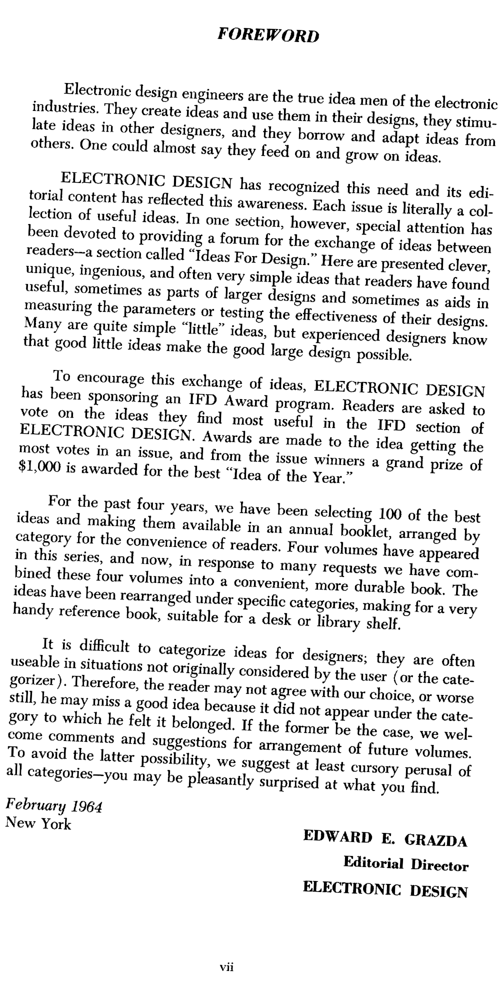

In [8]:
from sparkocr.utils import display_image

images_path = "./mixed_formats/*.png"
images_df = spark.read.format("binaryFile").load(images_path).sort("path")

display_images(BinaryToImage().setImageType(ImageType.TYPE_3BYTE_BGR).transform(images_df), "image")

Now the turn for the PDFs


    Image #0:
    Origin: file:/home/ubuntu/dataloader_pipelines/mixed_formats/report.pdf
    Resolution: 300 dpi
    Width: 4241 px
    Height: 2650 px
    Mode: 10
    Number of channels: 1


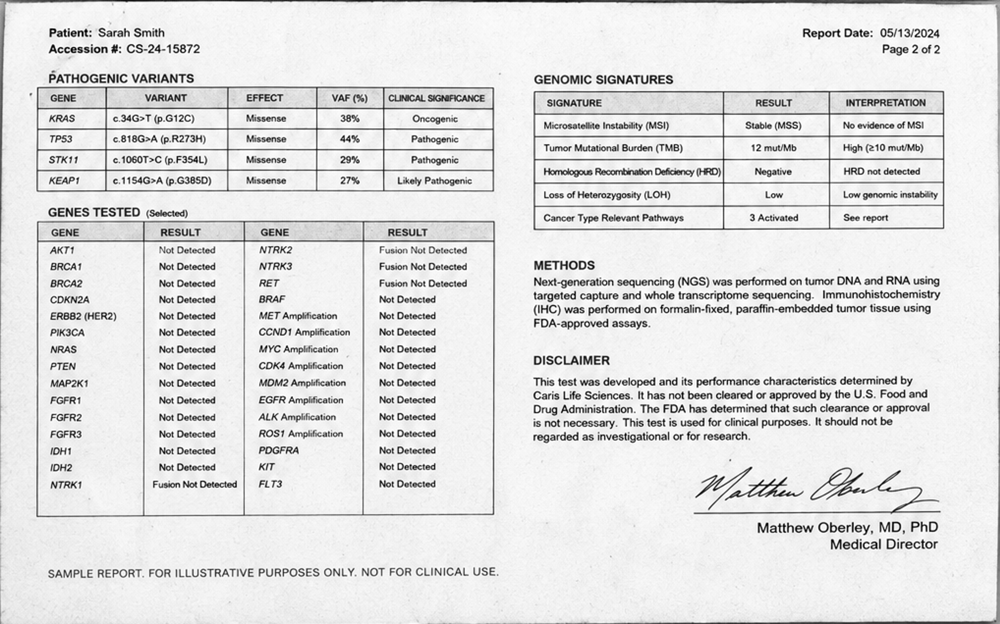


    Image #1:
    Origin: file:/home/ubuntu/dataloader_pipelines/mixed_formats/h_and_p.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: 10
    Number of channels: 1


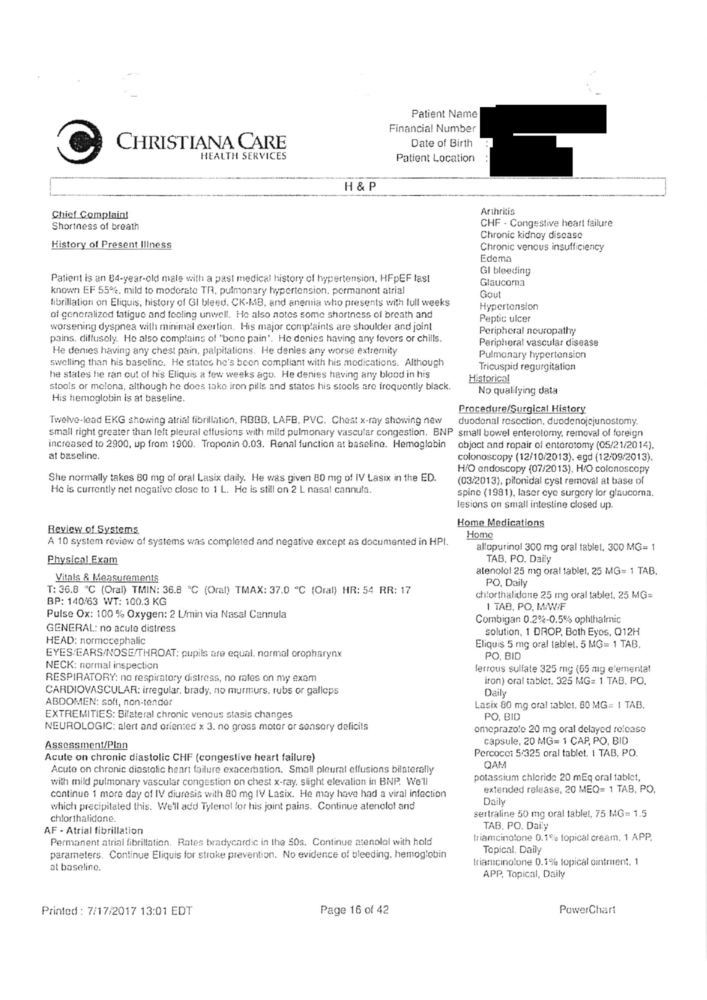


    Image #2:
    Origin: file:/home/ubuntu/dataloader_pipelines/mixed_formats/report.pdf
    Resolution: 300 dpi
    Width: 4254 px
    Height: 3770 px
    Mode: 10
    Number of channels: 1


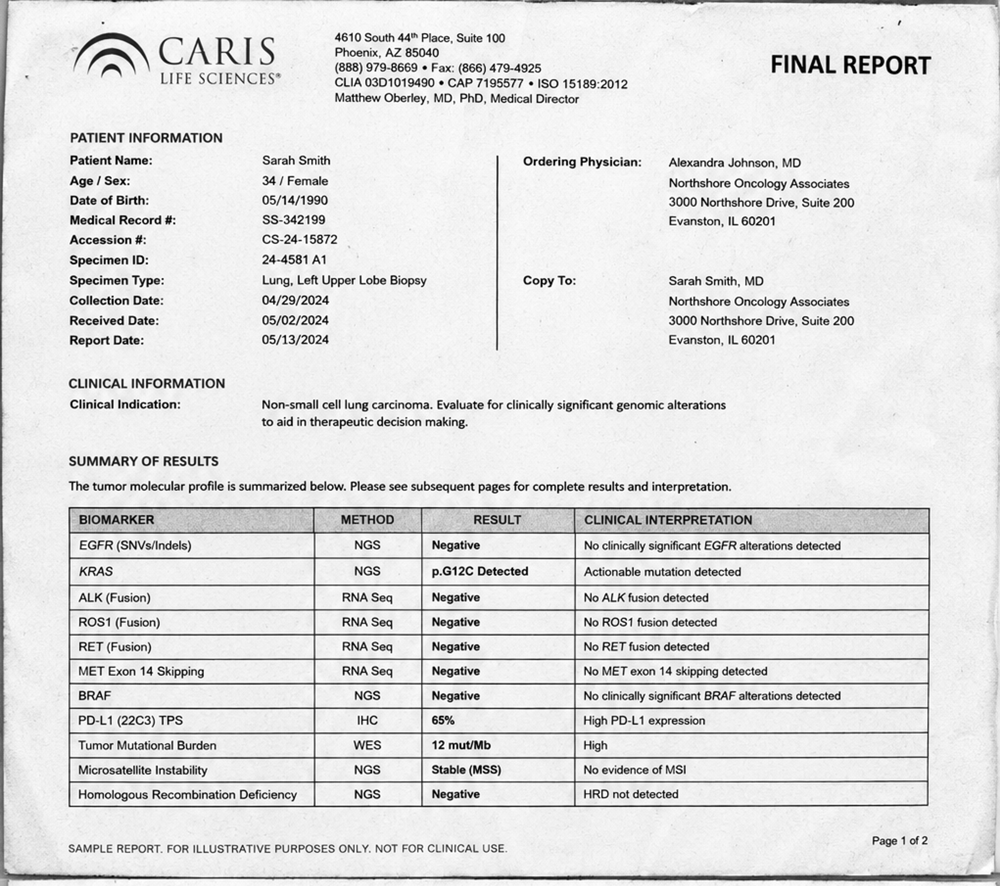


    Image #3:
    Origin: file:/home/ubuntu/dataloader_pipelines/mixed_formats/h_and_p.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: 10
    Number of channels: 1


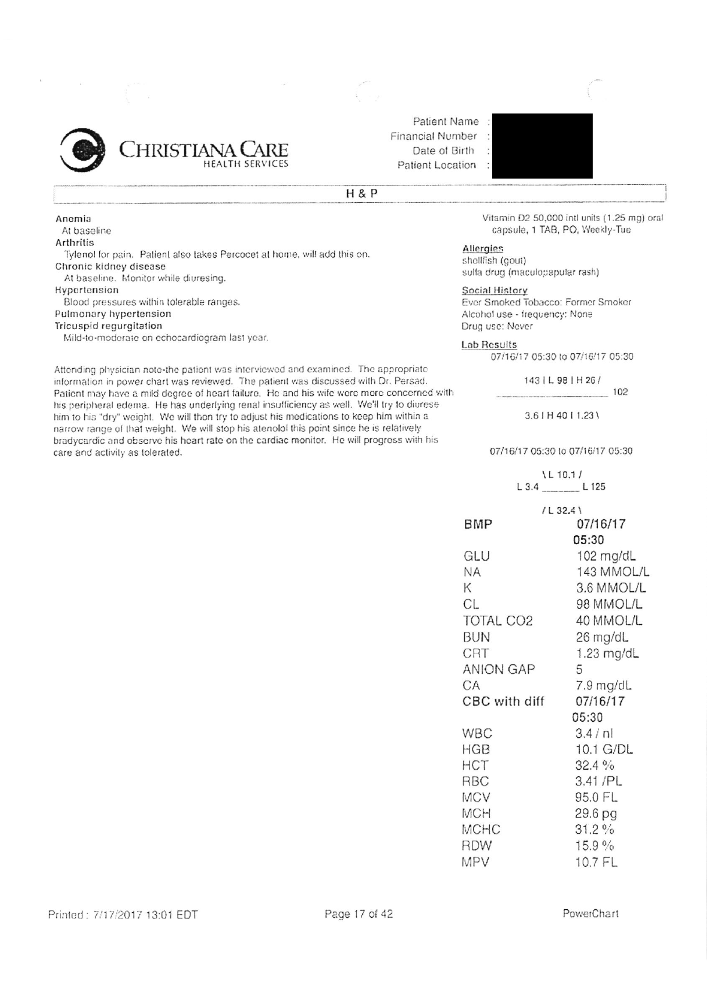


    Image #4:
    Origin: file:/home/ubuntu/dataloader_pipelines/mixed_formats/forms.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: 10
    Number of channels: 1


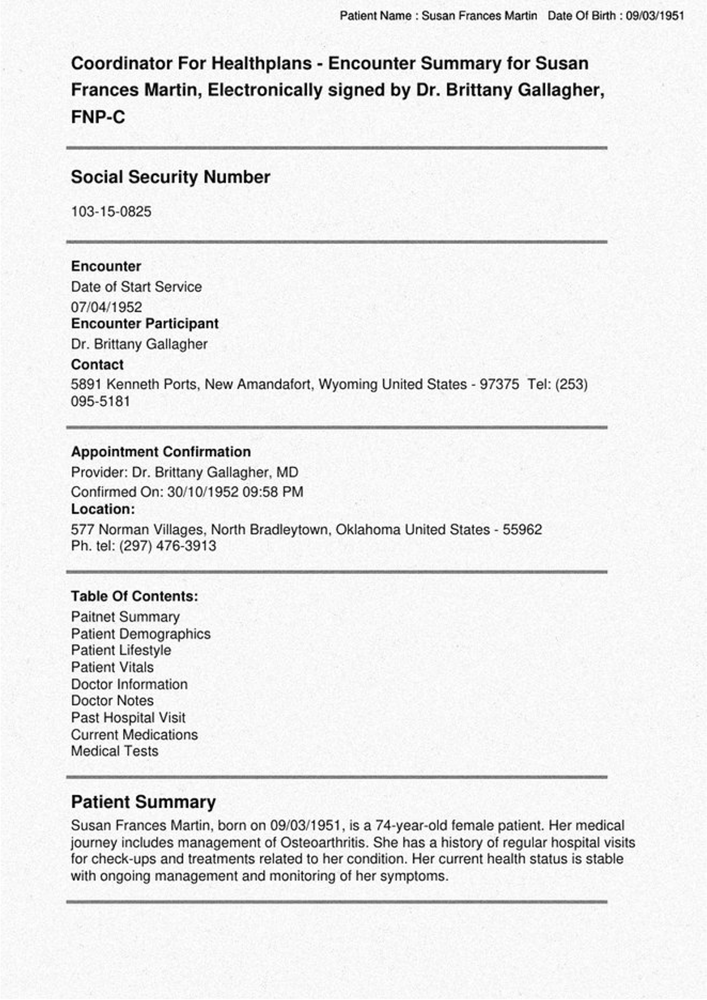

In [4]:
from sparkocr.utils import display_pdf

pdfs_path = "./mixed_formats/*.pdf"
pdfs_df = spark.read.format("binaryFile").load(pdfs_path).sort("path")

from sparkocr.utils import display_pdf_file
display_pdf(pdfs_df)

# Pretrained Pipelines
## Table Pipelines

### doc_data_loader_digital_hybrid_tables_vlm1
In this simple pipeline we can use the predefined pipeline to handle a mix of scanned(containing images), digital PDFs(containing digital text), and images as well. The output is going to be returned in a Dataframe column(`merged_text`), and it will contain texts coming from all sources.</br>
You could even have a single PDF file with a mix of digital and scanned pages.</br>


In [6]:
from pyspark.ml import PipelineModel
from sparkocr.pretrained import *

pipeline = PretrainedPipeline('doc_data_loader_digital_hybrid_tables_vlm1', 'en', 'clinical/ocr')

doc_data_loader_digital_hybrid_tables_vlm1 download started this may take some time.
Approx size to download 1.5 GB
[OK!]


### [Optional] Performance Tricks

In [ ]:
# Put a limit on image size.
pipeline.model.stages[2].setMaxImageWidth(1250)
# Send the model to GPU
pipeline.model.stages[-3].setNGpuLayers(99)

### Call the pipeline
We are listing the 'mixed_pdfs' folder, that one contains two PDF files, one is scanned and the other is digital. You can open them yourself and verify.

In [6]:
all_files_path = './mixed_formats/*'
all_files_df = spark.read.format("binaryFile").load(all_files_path).cache()

result = pipeline.transform(all_files_df).cache()

### Results
Note: to avoid truncation, using collect() on just the text column,
`merged_text` -> column collecting results from multiple pipeline components(digital text, VLM, OCR).

In [32]:
for t in result.select("merged_text").collect():
    print(t.merged_text.replace("\\n", "\n"))
    print("*"*20)

FOREWORD
Electronic design engineers are the true idea men of the electronic
industries. They create ideas and use them in their designs, they stimu-
late ideas in other designers, and they borrow and adapt ideas from
others. One could almost say they feed on and grow on ideas.
ELECTRONIC DESIGN has recognized this need and its edi-
torial content has reflected this awareness. Each issue is literally a col-
lection of useful ideas. In one section, however, special attention has
been devoted to providing a forum for the exchange of ideas between
readers—a section called “Ideas For Design.” Here are presented clever,
unique, ingenious, and often very simple ideas that readers have found
useful, sometimes as parts of larger designs and sometimes as aids in
measuring the parameters or testing the effectiveness of their designs.
Many are quite simple “little” ideas, but experienced designers know
that good little ideas make the good large design possible.

To encourage this exchange of idea

### doc_data_loader_digital_hybrid_tables_vlm2

In [5]:
from sparkocr.pretrained import PretrainedPipeline
pipeline = PretrainedPipeline('doc_data_loader_digital_hybrid_tables_vlm2', 'en', 'clinical/ocr')

# disable some ugly messages.
pipeline.model.stages[1].setIgnoreNonPdf(True)
pipeline.model.stages[2].setMaxImageWidth(1050)
pipeline.model.stages[-3].setNGpuLayers(99)


result = pipeline.transform(all_files_df).cache()

for t in result.select("merged_text").collect():
    print(t.merged_text.replace("\\n", "\n"))
    print("*"*20)

doc_data_loader_digital_hybrid_tables_vlm2 download started this may take some time.
Approx size to download 1.3 GB
[ | ]

26/07/02 19:05:33 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/07/02 19:05:33 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.


doc_data_loader_digital_hybrid_tables_vlm2 download started this may take some time.
Approximate size to download 1.3 GB
Download done! Loading the resource.


Traceback (most recent call last):
  File "/home/jose/spark-ocr/sparkocr/lib/python3.12/site-packages/pyspark/serializers.py", line 437, in dumps
    return cloudpickle.dumps(obj, pickle_protocol)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/jose/spark-ocr/sparkocr/lib/python3.12/site-packages/pyspark/cloudpickle/cloudpickle_fast.py", line 73, in dumps
    cp.dump(obj)
  File "/home/jose/spark-ocr/sparkocr/lib/python3.12/site-packages/pyspark/cloudpickle/cloudpickle_fast.py", line 563, in dump
    return Pickler.dump(self, obj)
           ^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/jose/spark-ocr/sparkocr/lib/python3.12/site-packages/pyspark/cloudpickle/cloudpickle_fast.py", line 653, in reducer_override
    return self._function_reduce(obj)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/jose/spark-ocr/sparkocr/lib/python3.12/site-packages/pyspark/cloudpickle/cloudpickle_fast.py", line 526, in _function_reduce
    return self._dynamic_function_reduce(obj)
           

[ / ]

26/07/02 19:05:35 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/07/02 19:05:35 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.


doc_data_loader_digital_hybrid_tables_vlm2 download started this may take some time.
Approximate size to download 1.3 GB
Download done! Loading the resource.
[ — ]Extracted 'libjllama.so' to '/tmp/libjllama.so'
[ \ ]

ggml_cuda_init: found 1 CUDA devices (Total VRAM: 7807 MiB):
  Device 0: NVIDIA GeForce RTX 4070 Laptop GPU, compute capability 8.9, VMM: yes, VRAM: 7807 MiB
                                                                                

[OK!]


[Stage 28:====================================================>   (15 + 1) / 16]

"
## PATHOGENIC VARIANTS

| GENE | VARIANT | EFFECT | VAF (%) | CLINICAL SIGNIFICANCE |
| :--- | :--- | :--- | :--- | :--- |
| KRA5 | c.34G>T (p.G12C) | Missense | 38% | Oncogenic |
| TP53 | c.818G>A (p.R273H) | Missense | 44% | Pathogenic |
| STK11 | c.1060T>C (p.F354L) | Missense | 29% | Pathogenic |
| KEAP1 | c.1154G>A (p.G385D) | Missense | 27% | Likely Pathogenic |

## GENES TESTED (Selected)

| GENE | RESULT | GENE | RESULT |
| :--- | :--- | :--- | :--- |
| AKT1 | Not Detected | NTRK2 | Fusion Not Detected |
| BRCA1 | Not Detected | NTRK3 | Fusion Not Detected |
| BRCA2 | Not Detected | RET | Fusion Not Detected |
| CDKN2A | Not Detected | BRAF | Not Detected |
| ERB82 (HER2) | Not Detected | MET Amplification | Not Detected |
| PIK3CA | Not Detected | CCND1 Amplification | Not Detected |
| NRAS | Not Detected | MYC Amplification | Not Detected |
| PTEN | Not Detected | CDK4 Amplification | Not Detected |
| MAP2K1 | Not Detected | MDM2 Amplification | Not Detected |
| FGFR1 | Not

In [7]:
result.select("exception").show(truncate=False)

+-----------------------------------------------------+
|exception                                            |
+-----------------------------------------------------+
|null ImageToText_1c4830dc120b: Input is not an image.|
|null                                                 |
|null ImageToText_1c4830dc120b: Input is not an image.|
|null ImageToText_1c4830dc120b: Input is not an image.|
|null ImageToText_1c4830dc120b: Input is not an image.|
+-----------------------------------------------------+



## Mixed Digital/Ocr Pipelines

### doc_data_loader_digital_hybrid

In [11]:
from sparkocr.pretrained import PretrainedPipeline
pipeline = PretrainedPipeline('doc_data_loader_digital_hybrid', 'en', 'clinical/ocr')

result = pipeline.transform(all_files_df).cache()

for t in result.select("text").collect():
    print(t.text.replace("\\n", "\n"))
    print("*"*20)



                     Smithh Patient: Sarahh                                                                                       Report Date; 05/13/2024 Accession CS 24-15872 Page 2  of  2 PATHOGENIC VARIANTS GGENNOMIC SIGNATUURES GENE VARIANT EFFECT SIGIFICANCE SIGNATURE RESSULT INTERPRETATION KRAS C.34G-T (p.G12C) Orcogenic (MSS) of  MSI MetosaIeg (Msi Stable evicencc TP53 c.818GG-A (pR273H) Pathogenic Tumoor Mutaticnal Burrden Muumb Hiigh (210 Muunb)) 4060T-C FJSAL) Ao As sense pathoceenic Haxxnooga Recomcnalin Defoency (HRDI HRD Aeqaie 4Oe OeeCeo KeAPI C1546-A G3eSD) Mssense Painogenic LosS Heterozygositt (LOH) Lo inshabiie TESTED GENES (Sclecledi Canccr Relevani Path oys Acuvuled reoont GENE RRESULT GENE RESULTT Delece Dueee METHODS BRCAT Detecied NtRK3 Fusion Detecle d (NNGS) DDNA and RNA Next-generation seequuencing perfommed Mumcm using BRCAZ Detecled Fuliom Not Deleciee WOS whole sequencing: Immunohistochemistry targeted capture anc transcnptome CDKNZA Detecico BRAF Dclecic

### doc_data_loader_digital_easy

In [15]:
from sparkocr.pretrained import PretrainedPipeline
pipeline = PretrainedPipeline('doc_data_loader_digital_easy', 'en', 'clinical/ocr')

result = pipeline.transform(all_files_df).cache()

for t in result.select("merged_text").collect():
    print(t.merged_text.replace("\\n", "\n"))
    print("*"*20)


                                             4610 Soulh 44th Place Suite 100 CCARRIS Phoenix 85040       FINAALL   REPORT 979 (888) ~8669 Fax' (866) 479-- -4925 LIFE SCIENCES" CLIA 03010119490 CAP 7195577 ISO 15189.2012 Matthew Obberley; PhD Director PATIENT INFORMATION Patient Name: Sarah Smith Ordering Physician: Alexaandra Johnsonn; MD Age Sex: Female Nortthshore Oncology Associates 05/14//1990 Date of Birtthh: 3000 Northhshoree Driive Suite 200 SS -342199 Medical Record Evanston; 60201 Acccession CS- -24-15872 Specimen 24--4581 AT Sppecimen Type: Lung; Leftt UUpper Biopsy Copy Sarahh Lobe To; Smith; MD Collection Date: 04//229/20224 Northshore Oncology Associatees 05/02//20024 Recceived DDatte: 3000 Northhshore Driive; Suitee 2200 05/13/20224 Evanston; 60201 Report Datte: CLINICAL INFORRMATION CClinical Indicaation: ~small cell Evaaluate for clinically significant Iung carcinoma genomic alterations aid thherappeutic decision making: LOO SUMMARY OF REESULTS Thee profile summarized 

## Forms Pipelines

### doc_data_loader_digital_hybrid_tables_forms_vlm1

In [ ]:
from sparkocr.pretrained import PretrainedPipeline
pipeline = PretrainedPipeline('doc_data_loader_digital_hybrid_tables_forms_vlm1', 'en', 'clinical/ocr')

result = pipeline.transform(all_files_df).cache()

In [10]:
for t in result.select("text").collect():
    print(t.text.replace("\\n", "\n"))
    print("*"*20)


Patient Name
Financial Number
CHRISTIANA CARE
Date of Birth
HEALTH SERVICES
Patient Locaiion
moernrrastnbncein
—
en er ranenn my
—
wae
—
a
oe
H & P
_
a
ee
Anemia
Vitamin D2 50,000 int! units (1.25 mg) oral
At baseline
capsule, 1 TAB, PO, Weesly-Tue
Arthritis
Allergies
Tylenol for pain, Palienl alse takes Percocet al home, will add this on.
Chronic kidney disease
sholliish (Gout)
sulfa drug (maculopapuler rash)
At baseline. Monitor while divresing.
Hypertension
Social History
Ever Smoked Tobacco: Former Smoker
Blood pressures within tolerable ranges.
Pulmonary hypertension
Alcohol use - frequency: None
Tricuspid regurgitation
Drug use: Never
Mild-to-moderaie on echocardiogram last year
Lab Results
07/16/17 05:30 to O7/16/17 05:30
Attending physician note-the patient was interviewed and examined. The appropriate
143 1L 981 26/
information in power chart was reviewed. The patient was discussed wilh Or, Persad.
Patient may have & mild degrec of heart failure. He and his wife were more con

In [23]:
result.printSchema()

root
 |-- path: string (nullable = true)
 |-- pagenum: integer (nullable = true)
 |-- has_complex: boolean (nullable = false)
 |-- simple_extraction: struct (nullable = true)
 |    |-- origin: string (nullable = true)
 |    |-- height: integer (nullable = false)
 |    |-- width: integer (nullable = false)
 |    |-- nChannels: integer (nullable = false)
 |    |-- mode: integer (nullable = false)
 |    |-- resolution: integer (nullable = false)
 |    |-- data: binary (nullable = true)
 |-- complex_extraction: struct (nullable = true)
 |    |-- origin: string (nullable = true)
 |    |-- height: integer (nullable = false)
 |    |-- width: integer (nullable = false)
 |    |-- nChannels: integer (nullable = false)
 |    |-- mode: integer (nullable = false)
 |    |-- resolution: integer (nullable = false)
 |    |-- data: binary (nullable = true)
 |-- digital_text: string (nullable = true)
 |-- exception: string (nullable = true)
 |-- prompt: string (nullable = false)
 |-- caption_document: ar

### doc_data_loader_digital_hybrid_tables_forms_vlm2

In [ ]:
from sparkocr.pretrained import PretrainedPipeline
pipeline = PretrainedPipeline('doc_data_loader_digital_hybrid_tables_forms_vlm2', 'en', 'clinical/ocr')

result = pipeline.transform(all_files_df).cache()